# Practice 4 — Dự báo Chuỗi thời gian Đa biến (Multivariate Time Series Forecasting)

**Bộ dữ liệu chính thức:** `UCI ElectricityLoadDiagrams20112014` (Bồ Đào Nha, nhóm 321 khách hàng ổn định giai đoạn 2012–2014, chuẩn hóa 1 giờ UTC & xử lý DST) + Thời tiết tái phân tích `Open-Meteo ERA5` (Lisbon 50%, Porto 35%, Coimbra 15%).  
**Các mô hình đối chiếu:** `Persistence`, `Seasonal-24`, `Seasonal-168`, `Stationary VAR`, `GPU XGBoost (+ SHAP)` và `GPU PyTorch LSTM` (chạy trên **NVIDIA GeForce RTX 5050 CUDA**).  
**Tài liệu tham chiếu:** `references/chapter4-5.pdf` — *Chương 4-5: Mô hình Dự đoán Chuỗi thời gian Đa biến*.

---

## 0. Phát biểu bài toán & Giao thức thực nghiệm (Problem Formulation)

Tại cuối mỗi giờ $t$ (origin), ta quan sát véc-tơ 4 biến:

$$
X_t = [\text{load}_t,\; \text{temp}_t,\; \text{humidity}_t,\; \text{wind\_speed}_t]
$$

Mục tiêu là dự báo phụ tải thực tế ở bước tiếp theo $\hat{y}_{t+1} = \widehat{\text{load}}_{t+1}$ (đơn vị **kW**) trên tập dữ liệu hoàn toàn liên tục, không rò rỉ tương lai. Ba chỉ số đánh giá chính trên thang đo gốc:
- **MAE:** $\frac{1}{N}\sum_{i=1}^N |y_i - \hat{y}_i|$
- **RMSE:** $\sqrt{\frac{1}{N}\sum_{i=1}^N (y_i - \hat{y}_i)^2}$
- **MAPE (%):** $\frac{100}{N}\sum_{i=1}^N \left|\frac{y_i - \hat{y}_i}{y_i}\right|$ (trên $y_i \neq 0$)


In [1]:
from pathlib import Path
import json
import re
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if not (ROOT / 'outputs').exists() and (ROOT.parent / 'outputs').exists():
    ROOT = ROOT.parent

def show_doc(rel_path: str) -> None:
    text = (ROOT / rel_path).read_text(encoding='utf-8')
    lines = text.splitlines()
    if lines and lines[0].startswith('# '):
        lines = lines[1:]
    cleaned = re.sub(r'^(#{1,4}) ', lambda m: '#' * min(len(m.group(1)) + 1, 5) + ' ', '\n'.join(lines).strip(), flags=re.M)
    display(Markdown(cleaned))

env = json.loads((ROOT / 'runs/v2/s0_env/environment.json').read_text(encoding='utf-8'))
split = json.loads((ROOT / 'datasets/processed/split_manifest.json').read_text(encoding='utf-8'))
scaler = json.loads((ROOT / 'runs/v2/s4_prep/scaler.json').read_text(encoding='utf-8'))
test_metrics = pd.read_csv(ROOT / 'outputs/tables/test_metrics.csv')
dm_test = pd.read_csv(ROOT / 'outputs/tables/dm_test.csv')
grouped_errors = pd.read_csv(ROOT / 'runs/v2/s8_eval/artifacts/grouped_errors.csv')

env_table = pd.DataFrame([{
    'GPU': env['gpu']['device_name'],
    'VRAM (MB)': env['gpu']['vram_total_mb'],
    'CUDA': env['gpu']['torch_cuda_version'],
    'PyTorch': env['packages']['torch'],
    'XGBoost': env['packages']['xgboost'],
    'SHAP': env['packages']['shap'],
    'Statsmodels': env['packages']['statsmodels'],
}])
display(env_table)


,GPU,VRAM (MB),CUDA,PyTorch,XGBoost,SHAP,Statsmodels
0,NVIDIA GeForce RTX 5050,8150.6,13.0,2.14.1+cu130,3.4.1,0.54.1,0.14.6


## 1. Dữ liệu chính thức, Xử lý DST & Phân chia theo thời gian (S1–S3)

Dữ liệu được tải trực tiếp từ nguồn UCI 321 chính thức (`LD2011_2014.txt`) và Open-Meteo ERA5 (có kiểm chứng SHA256), chuẩn hóa về lưới 1 giờ UTC liên tục (`26.304` giờ) sau khi loại bỏ giai đoạn onboarding không đồng nhất năm 2011 và xử lý chuyển giờ mùa hè/đông (`Europe/Lisbon`). Dữ liệu được chia theo thời gian không shuffle tỷ lệ **70% / 15% / 15%**, kèm **3-fold Expanding-Window CV** bên trong Train.


In [2]:
split_df = pd.DataFrame([
    {'Split': k, 'Rows': v['row_count'], 'Share (%)': 100*v['row_count']/split['total_rows'], 'Start (UTC)': v['start_utc'], 'End (UTC)': v['end_utc']}
    for k, v in split['splits'].items()
])
display(split_df.style.format({'Rows': '{:,}', 'Share (%)': '{:.2f}'}).hide(axis='index'))
show_doc('docs/results/data_audit.md')
show_doc('docs/results/data_contract.md')


Split,Rows,Share (%),Start (UTC),End (UTC)
train,"18,412",70.00,2012-01-01T00:00:00+00:00,2014-02-06T03:00:00+00:00
validation,"3,945",15.00,2014-02-06T04:00:00+00:00,2014-07-20T12:00:00+00:00
test,"3,947",15.01,2014-07-20T13:00:00+00:00,2014-12-31T23:00:00+00:00


- **Dataset:** UCI ElectricityLoadDiagrams20112014 + Open-Meteo ERA5 Portugal
- **UCI URL:** https://archive.ics.uci.edu/static/public/321/electricityloaddiagrams20112014.zip (`CC BY 4.0`)
- **UCI Archive SHA256:** `f6c4d0e0df12ecdb9ea008dd6eef3518adb52c559d04a9bac2e1b81dcfc8d4e1`
- **UCI `LD2011_2014.txt` SHA256:** `d51565f2cb5a6b768d06ba1bbd3c084c6e2f3aab07f00c6f2dcb80e90175124b`
- **Weather Source:** Open-Meteo ERA5 Historical Archive (`CC BY 4.0 (ECMWF ERA5 via Open-Meteo)`)
- **Weather CSV SHA256:** `ed0e577dff8e93ae0a0eac31bafa2a5fde91325cb9b499e2b7308262267df19b`

### 1. UCI ElectricityLoadDiagrams20112014 Raw Quality

- Rows: **140,256** (15-min intervals), Clients: **370**
- Local span: `2011-01-01 00:15:00` → `2015-01-01 00:00:00`
- Ordered: `True`, Duplicate timestamps: `0`
- Missing cells: `0`, Negative cells: `0`
- Total active power (kW): min `342.60`, mean `195,556.94`, max `452,652.60`

#### Active Clients by Year (Onboarding Regime Check)

| Year | 15-min Rows | Min Active | Median Active | Max Active | Mean Total kW | Zero-Total Rows |
|---:|---:|---:|---:|---:|---:|---:|
| 2011 | 35,039 | 155 | 158.0 | 160 | 122,716.7 | 0 |
| 2012 | 35,136 | 119 | 323.0 | 332 | 212,317.4 | 0 |
| 2013 | 35,040 | 128 | 336.0 | 349 | 222,736.8 | 0 |
| 2014 | 35,040 | 117 | 364.0 | 369 | 224,410.9 | 0 |
| 2015 | 1 | 367 | 367.0 | 367 | 124,214.2 | 0 |

### 2. Open-Meteo ERA5 Portugal Weather Raw Quality

- Rows: **105,264** (`2011-01-01T00:00:00+00:00` → `2015-01-01T23:00:00+00:00`), Duplicate city-hour: `0`

| Variable | Min | Max | Unit | Physical Bounds Pass |
|---|---:|---:|---|---|
| `temp_c` | -2.900 | 39.300 | °C | `True` |
| `humidity` | 14.000 | 100.000 | % | `True` |
| `wind_speed` | 0.000 | 16.020 | m/s | `True` |

| City | Weight | Rows | Unique Timestamps | Missing (T/H/W) |
|---|---:|---:|---:|---|
| Coimbra | 0.15 | 35,088 | 35,088 | 0/0/0 |
| Lisbon | 0.50 | 35,088 | 35,088 | 0/0/0 |
| Porto | 0.35 | 35,088 | 35,088 | 0/0/0 |

- **Canonical CSV:** `canonical_hourly.csv` (SHA256: `85c575e07cc1e7be7d913e882122360ba0f536c531227c0e9087a26ff1311542`)
- **Source UCI SHA256:** `d51565f2cb5a6b768d06ba1bbd3c084c6e2f3aab07f00c6f2dcb80e90175124b`
- **Source Weather SHA256:** `ed0e577dff8e93ae0a0eac31bafa2a5fde91325cb9b499e2b7308262267df19b`
- **Rows:** **26,304** contiguous 1-hour UTC steps (`2012-01-01T00:00:00+00:00` → `2014-12-31T23:00:00+00:00`)
- **Stable Client Cohort:** **321 / 370** clients active in Jan 2012 (eliminates 2011 onboarding step-jump).
- **DST Handling (`Europe/Lisbon`):** Spring-forward non-existent zero-padded local hour excluded naturally upon UTC mapping; Fall-back doubled local hour halved across its two UTC hours (`6` flagged hours).
- **Weather Proxy:** Population-weighted ERA5 mean (Lisbon 0.50, Porto 0.35, Coimbra 0.15). Physical anomaly hours: `0`.

| Column | Unit / Type | Range / Summary |
|---|---|---|
| `timestamp_utc` | ISO-8601 UTC (`1h`) | `2012-01-01T00:00:00+00:00` .. `2014-12-31T23:00:00+00:00` |
| `load` | kW (`float64`) | min `75,765.82`, mean `203,577.33`, max `446,935.42`, missing `0` |
| `temp` | °C (`float64`) | `0.39` .. `35.99` |
| `humidity` | % (`float64`) | `21.90` .. `100.00` |
| `wind_speed` | m/s (`float64`) | `0.30` .. `14.02` |
| `load_observed` | `bool` | Exact mask of observed raw target |
| `dst_fallback_split` | `bool` | Marks October fall-back split hours |
| `weather_physical_anomaly` | `bool` | Marks physical out-of-range weather hours |

## 2. Khám phá dữ liệu chỉ trên tập Train (Train-Only EDA — S3)

Toàn bộ thống kê mô tả, tương quan Pearson/Spearman, phân tích mùa vụ theo giờ/thứ/tháng và ACF/PACF chỉ được tính trên `18.412` giờ đầu tiên (tập Train). Validation và Test hoàn toàn bị cách ly trong bước này.


- **Scope:** Train split only (`18,412` hours, `2012-01-01T00:00:00+00:00` → `2014-02-06T03:00:00+00:00`). Validation and test were never accessed.
- **Missing load:** `0` | **DST fall-back split hours:** `4` | **Weather physical anomalies:** `0`

### 1. Variable Distributions & Extrema (Train)

| Variable | Min | Mean | Std | Max | P0.5 | P99.5 | Missing |
|---|---:|---:|---:|---:|---:|---:|---:|
| `load` | 85,981.76 | 204,690.87 | 80,138.15 | 446,935.42 | 91,471.48 | 403,430.92 | 0 |
| `temp` | 0.39 | 15.33 | 5.62 | 35.99 | 4.19 | 31.49 | 0 |
| `humidity` | 21.90 | 75.93 | 15.43 | 100.00 | 32.71 | 98.35 | 0 |
| `wind_speed` | 0.30 | 3.94 | 1.73 | 13.96 | 0.91 | 9.45 | 0 |

### 2. Load–Weather Association (Train, Non-Causal)

| Weather Variable | Pearson r | Spearman ρ |
|---|---:|---:|
| `temp` | 0.6767 | 0.6018 |
| `humidity` | -0.6404 | -0.6016 |
| `wind_speed` | 0.1113 | 0.1202 |

### 3. Temporal Dependence (ACF)

- Lag 1h ACF: `0.9574`
- Lag 24h (daily) ACF: `0.9863`
- Lag 168h (weekly) ACF: `0.9623`

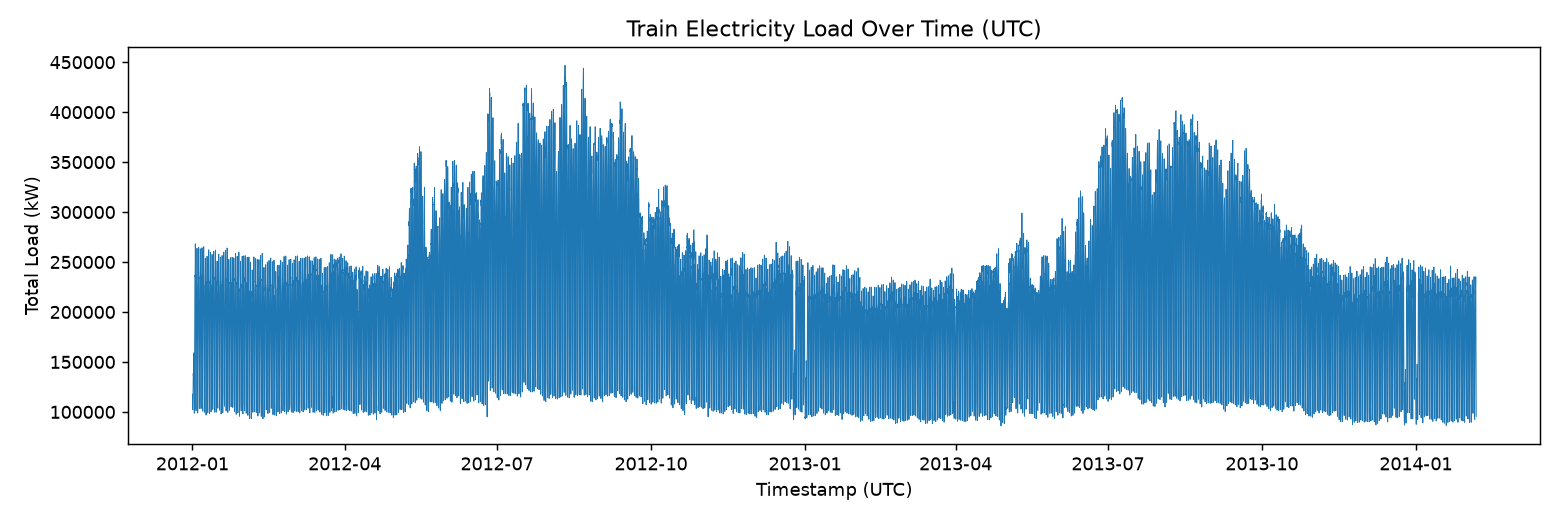

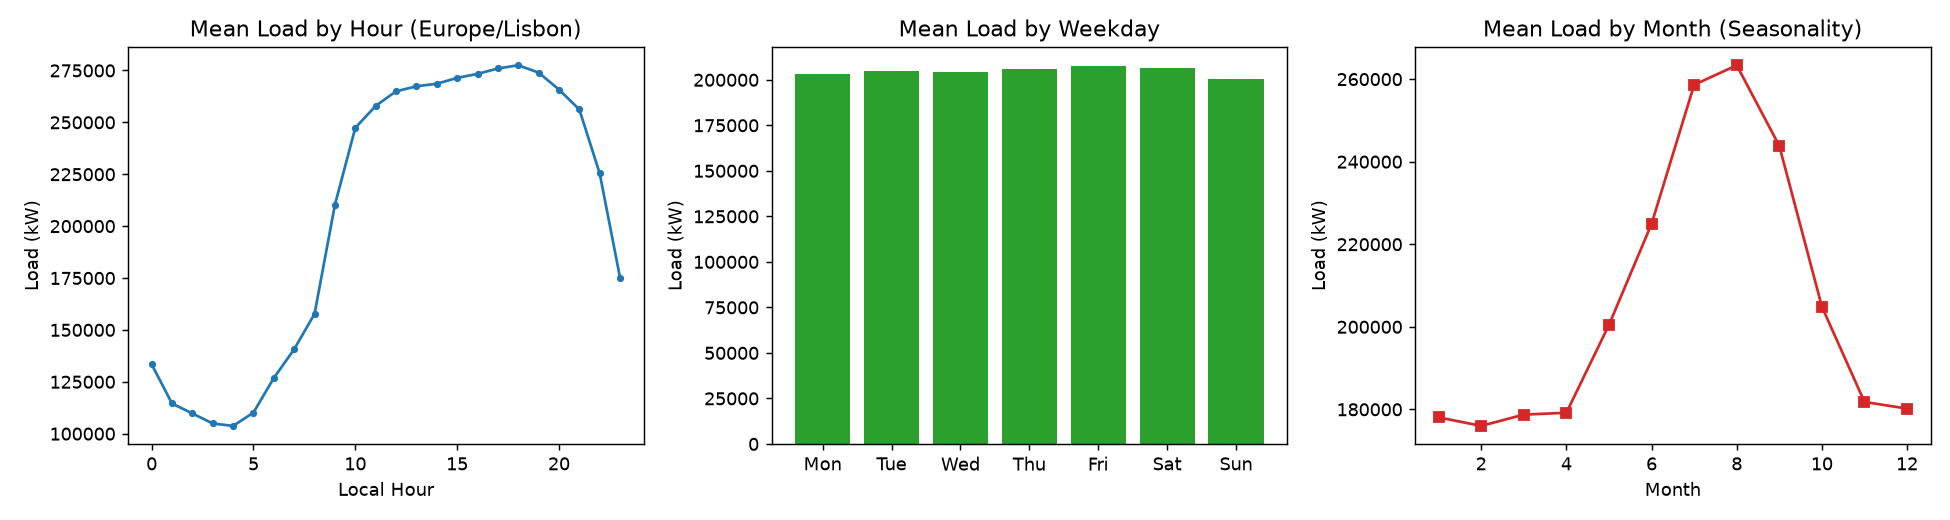

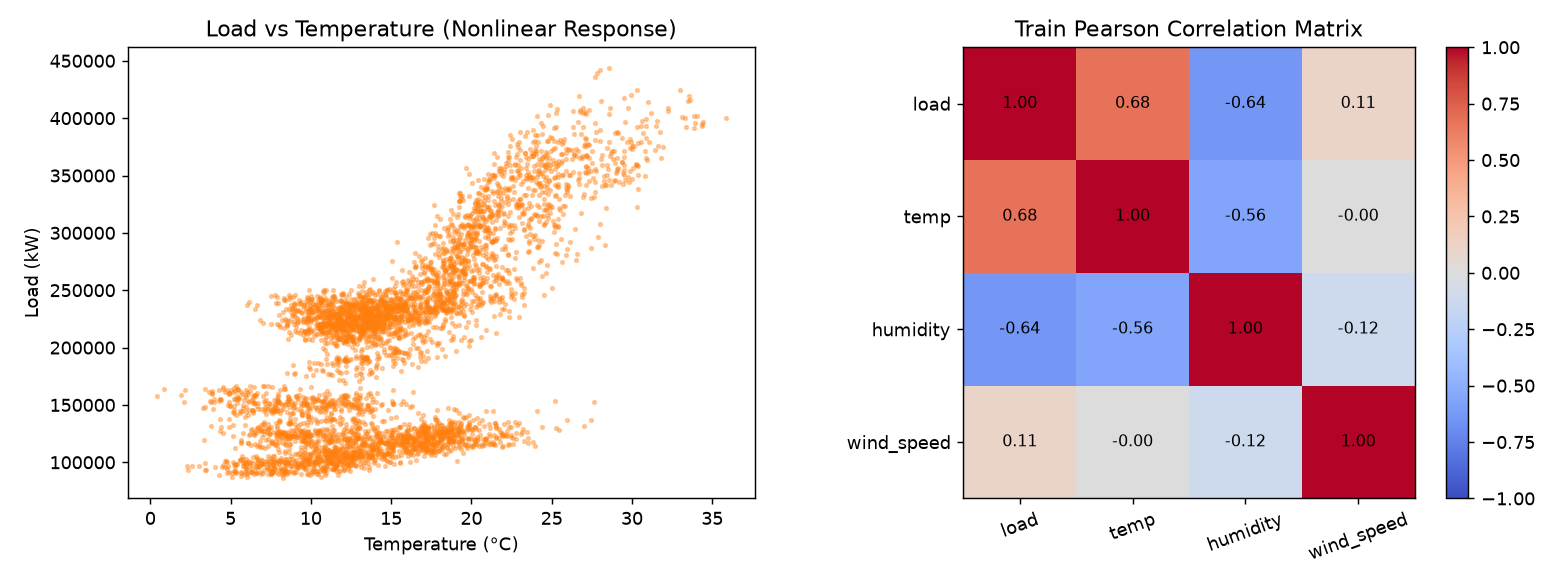

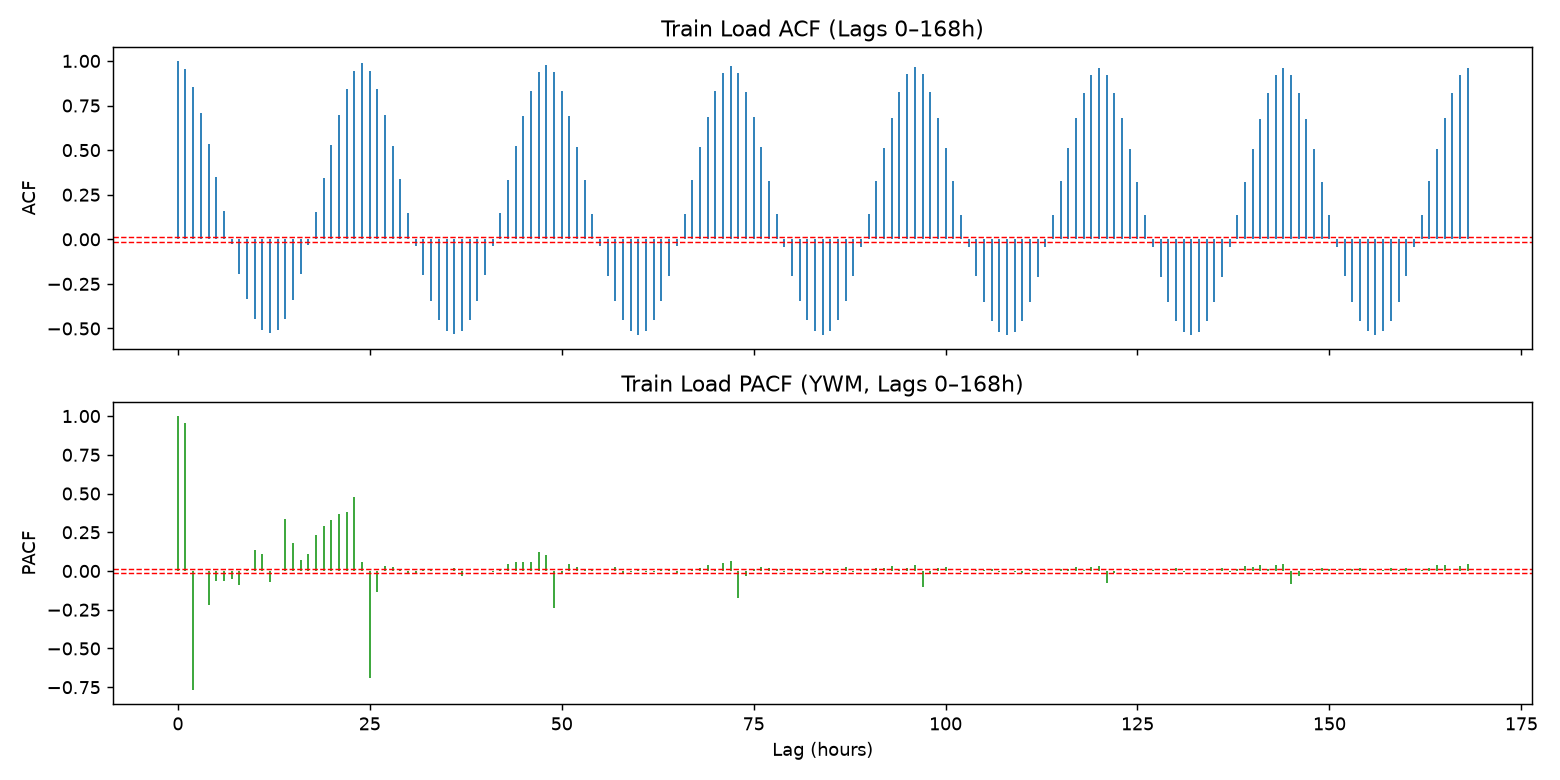

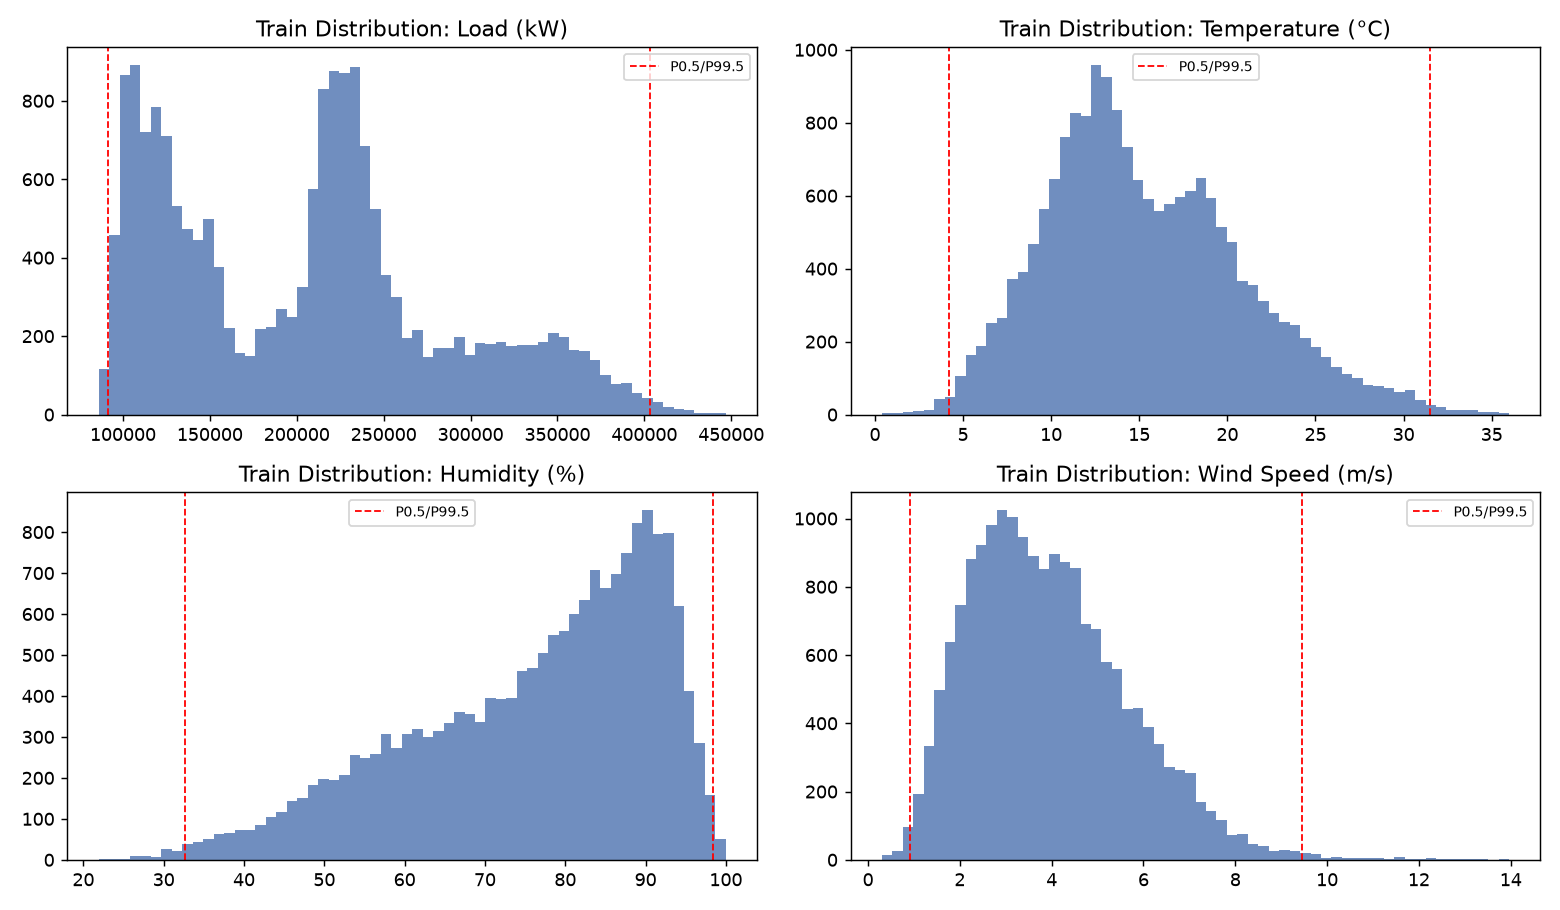

In [3]:
show_doc('docs/results/eda_findings.md')
for fn in ['eda_load_utc.png', 'eda_seasonality_profiles.png', 'eda_relationships.png', 'eda_acf_pacf.png', 'eda_distributions.png']:
    display(Image(filename=str(ROOT / 'outputs/figures' / fn)))


## 3. Tiền xử lý nhân quả & Tạo đặc trưng đa biến (S4)

- `StandardScaler` chỉ fit trên `18.412` mẫu Train và giữ cố định cho Validation/Test.
- Ngoài cửa sổ 24 giờ gốc (`96` lags), bộ đặc trưng mở rộng bổ sung **rolling stats** (`mean6h`, `mean24h`, `std24h`, `min24h`, `max24h`, `trend24h`, `diff1h`, `trend168h`), **lags dài hạn** (`lag47`, `lag167`), **9 biến lịch địa phương/DST/ngày lễ** tại `t+1`, và **6 biến tương tác chéo** (`load_per_temp_k`, `hdd_proxy`, `cdd_proxy`, `temp_x_humidity`, `temp_diff_1h`, `temp_diff_24h`) theo Slide 7 tài liệu `chapter4-5.pdf`.


In [4]:
scaler_df = pd.DataFrame({
    'Feature': scaler['feature_order'],
    'Train Mean': scaler['mean'],
    'Train Std': scaler['std'],
})
display(scaler_df.style.format({'Train Mean': '{:,.4f}', 'Train Std': '{:,.4f}'}).hide(axis='index'))
show_doc('docs/results/feature_dictionary.md')


Feature,Train Mean,Train Std
load_input,"204,690.8684","80,135.9710"
temp_input,15.3328,5.6195
humidity_input,75.9307,15.4294
wind_speed_input,3.9444,1.7271


- **Common Causal Context:** `168` hours (`t-167 .. t`) to predict observed raw `load(t+1)`.
- **Train Eligible:** `18,244` / `18,244`
- **Validation Eligible:** `3,945` / `3,945`
- **Total `XGB_full` Features:** `121`
- **LSTM Core Shape:** `(N, 24, 4)` | **LSTM Calendar Shape:** `(N, 24, 13)`

### Ablation Feature Subsets

| Subset | Count | Description |
|---|---:|---|
| `XGB_load_only` | 34 | 24h load lags + lag47/lag167 + 8 rolling load stats |
| `XGB_load_weather` | 104 | 96 base 24h multivariate lags + 8 rolling load stats |
| `XGB_load_calendar` | 43 | `XGB_load_only` + 9 local calendar/DST/holiday target features |
| `XGB_full` | 121 | All load, weather, calendar/DST/holiday, and 6 cross-variable interactions |

### Cross-Variable Interaction Features (Slide 7, `chapter4-5.pdf`)

- `load_per_temp_k`: `load_input(t) / (temp_input(t) + 273.15)`
- `hdd_proxy`: `max(0, 18.0 - temp_input(t))` (heating load nonlinearity)
- `cdd_proxy`: `max(0, temp_input(t) - 22.0)` (cooling load nonlinearity)
- `temp_x_humidity`: `temp_input(t) * humidity_input(t)`
- `temp_diff_1h`, `temp_diff_24h`: 1-hour and 24-hour temperature change at origin `t`

## 4. Các đường cơ sở & Mô hình Thống kê Cổ điển VAR (S5)

Kiểm định song song ADF và KPSS trên toàn bộ chuỗi Train cho thấy cả 4 biến không đạt dừng ở mức gốc (`level`). Tuân thủ Slide 5 (`chapter4-5.pdf`), mô hình được sai phân bậc 1 (`d=1`) và huấn luyện trên **100% tập Train (`18.411` giờ)** thay vì bị cắt xén như phiên bản cũ.


In [5]:
show_doc('docs/results/var_results.md')


- **Selected VAR:** `VAR_diff1` (`p=24`, `d=1`)
- **Selection Rationale:** Selected VAR_diff1 per chapter4-5.pdf Slide 5 (KPSS rejects level stationarity; diff1 achieves both ADF & KPSS stationarity and stable eigenvalues).
- **Training Rows Used:** `18,411` (100% of causal training history — fixes v1 62% data loss).

### 1. Stationarity Diagnostics (ADF + KPSS on Full Train)

| Variable | Level ADF p | Level KPSS p | Level Stationary? | Diff-1 ADF p | Diff-1 KPSS p | Diff-1 Stationary? |
|---|---:|---:|---|---:|---:|---|
| `load` | 0.01639 | 0.01 | `False` | 0 | 0.1 | `True` |
| `temperature` | 0.001105 | 0.01 | `False` | 0 | 0.1 | `True` |
| `humidity` | 3.999e-11 | 0.01304 | `False` | 0 | 0.1 | `True` |
| `wind_speed` | 1.593e-20 | 0.01 | `False` | 0 | 0.1 | `True` |

### 2. VAR Variants & Baseline Validation Comparison

| Model | d | p | Max |λ| | Whiteness p | MAE (kW) | RMSE (kW) | MAPE (%) |
|---|---:|---:|---:|---:|---:|---:|---:|
| `persistence` | - | - | - | - | 14,490.64 | 21,265.95 | 8.5874 |
| `seasonal24` | - | - | - | - | 5,792.47 | 8,846.94 | 2.9552 |
| `seasonal168` | - | - | - | - | 12,407.93 | 21,537.95 | 5.5045 |
| `VAR_diff1` | 1 | 24 | 0.999809 | 0 | 3,317.19 | 4,793.35 | 1.7830 |
| `VAR_level` | 0 | 24 | 0.999828 | 0 | 4,935.83 | 6,992.35 | 2.6693 |

## 5. Mô hình Machine Learning: GPU XGBoost, Ablation & SHAP (S6)

Huấn luyện trực tiếp trên **NVIDIA RTX 5050 (`device='cuda'`)** với 48 cấu hình Expanding-Window CV, tiếp theo là thí nghiệm Ablation 4 nhóm đặc trưng (`load_only` → `load_weather` → `load_calendar` → `full`) và phân tích đóng góp bằng **SHAP TreeExplainer**.


- **Device:** NVIDIA RTX 5050 (`device=cuda`, `tree_method=hist`)
- **CV-Selected Hyperparameters (3-fold Expanding CV on Train):** `max_depth=6`, `learning_rate=0.02`, `min_child_weight=5.0`, `colsample_bytree=0.7`, `reg_lambda=5.0` (CV RMSE `5,252.61 ± 770.40 kW`)
- **Selected Winning Subset on Validation:** **`XGB_full`**
- **SHAP Additivity Max Error:** `0.631271 kW`

### 1. Validation Ablation Study

| Subset | Features | Trees | Fit (s) | MAE (kW) | RMSE (kW) | MAPE (%) |
|---|---:|---:|---:|---:|---:|---:|
| `XGB_full` | 121 | 707 | 3.41 | 2,996.39 | 4,358.22 | 1.5564 |
| `XGB_load_calendar` | 43 | 506 | 1.92 | 3,036.55 | 4,463.62 | 1.5775 |
| `XGB_load_weather` | 104 | 528 | 2.57 | 3,134.90 | 4,514.44 | 1.6529 |
| `XGB_load_only` | 34 | 623 | 2.46 | 3,106.24 | 4,577.17 | 1.6185 |

### 2. SHAP Group Attribution (`XGB_full`)

| Feature Group | Sum of Mean |SHAP| (kW) |
|---|---:|
| `load_lags_24h` | 39,096.84 |
| `load_rolling_weekly` | 28,740.64 |
| `cross_interactions` | 2,700.73 |
| `temperature_lags` | 1,702.68 |
| `calendar_dst_holiday` | 1,372.96 |
| `humidity_lags` | 739.89 |
| `wind_speed_lags` | 324.71 |

### 3. Top 10 Individual Features by Mean |SHAP|

| Feature | Group | Mean |SHAP| (kW) |
|---|---|---:|
| `lag23_load` | `load_lags_24h` | 31,805.18 |
| `lag167_load` | `load_rolling_weekly` | 18,532.06 |
| `lag47_load` | `load_rolling_weekly` | 6,291.63 |
| `lag00_load` | `load_lags_24h` | 4,474.62 |
| `trend24h` | `load_rolling_weekly` | 2,101.39 |
| `load_per_temp_k` | `cross_interactions` | 1,449.37 |
| `lag22_load` | `load_lags_24h` | 1,201.23 |
| `lag00_temperature` | `temperature_lags` | 1,056.58 |
| `temp_diff_24h` | `cross_interactions` | 451.01 |
| `target_hour_cos` | `calendar_dst_holiday` | 389.72 |

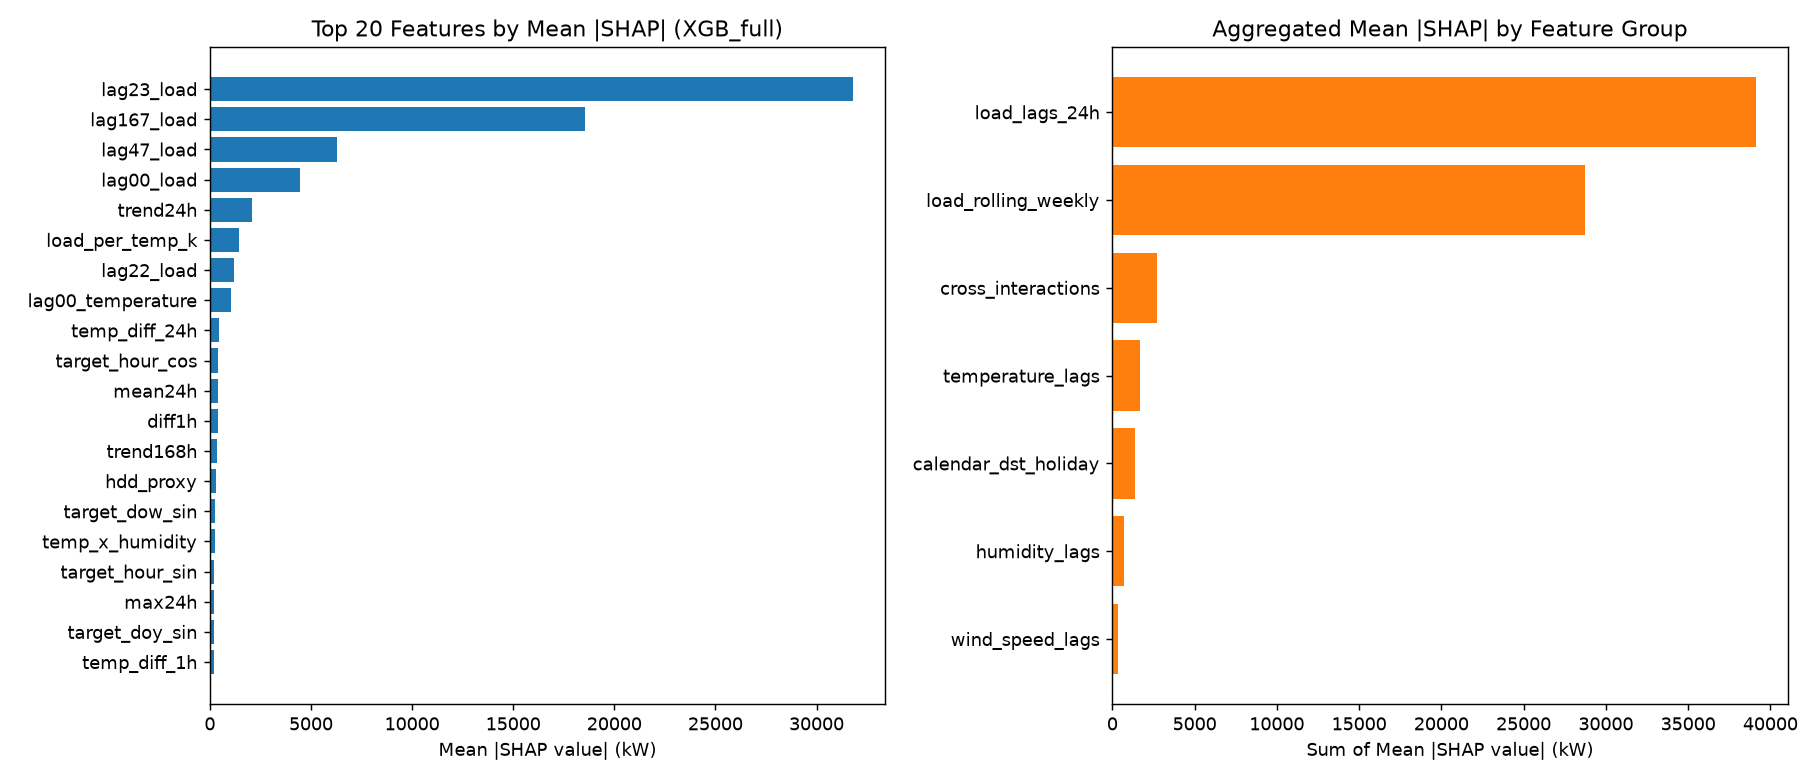

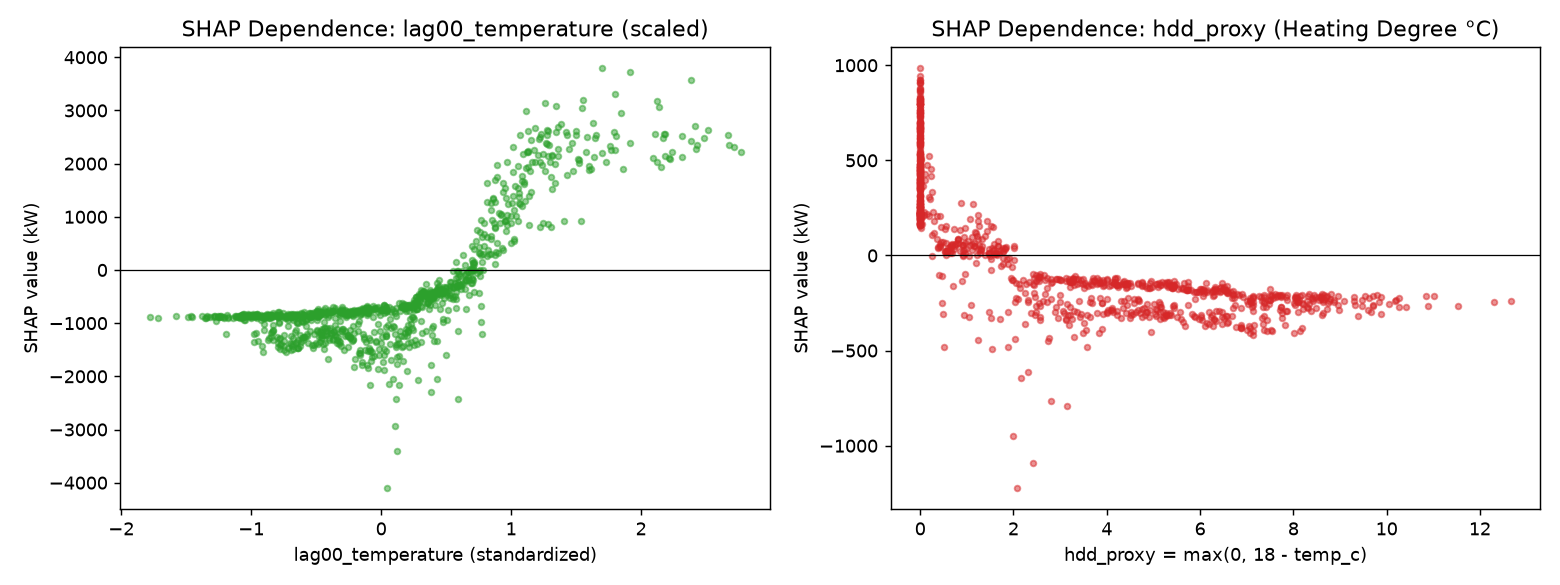

In [6]:
show_doc('docs/results/xgboost_findings.md')
for fn in ['xgb_shap_summary.png', 'xgb_shap_dependence_temp.png']:
    display(Image(filename=str(ROOT / 'outputs/figures' / fn)))


## 6. Mô hình Deep Learning: GPU PyTorch LSTM (S7)

Xây dựng bằng PyTorch CUDA (`LSTM(64) → LSTM(32) → Linear(1)`) trên RTX 5050, loại bỏ hoàn toàn các workaround CPU chậm trước đây; thực nghiệm đối chứng trên 4 biến thể (`24h_load_only`, `24h_core`, `24h_cal`, `168h_diag`) và kiểm định độ ổn định qua 3 random seeds (`42, 123, 2026`).


- **Device:** `cuda (NVIDIA GeForce RTX 5050)` (zero `np.repeat(64)` workaround; native `batch=1` & batched inference verified)
- **Selected Winning LSTM Variant:** **`LSTM_24h_cal`**

### 1. Variant & Ablation Comparison (Validation)

| Variant | Window | Input Dim | Params | Best/Stop Epoch | Fit (s) | Train MSE (scaled) | Val MSE (scaled) | MAE (kW) | RMSE (kW) | MAPE (%) |
|---|---:|---:|---:|---|---:|---:|---:|---:|---:|---:|
| `LSTM_24h_load_only` | 24h | 1 | 29,729 | 39/49 | 29.92 | 0.007155 | 0.005581 | 4,418.33 | 5,986.57 | 2.4220 |
| `LSTM_24h_core` | 24h | 4 | 30,497 | 37/47 | 26.93 | 0.004498 | 0.005473 | 4,115.95 | 5,928.51 | 2.2192 |
| `LSTM_24h_cal` | 24h | 13 | 32,801 | 19/29 | 18.29 | 0.005131 | 0.005427 | 4,096.36 | 5,903.38 | 2.1921 |
| `LSTM_168h_diag` | 168h | 13 | 32,801 | 19/29 | 19.90 | 0.007248 | 0.006467 | 4,700.52 | 6,444.57 | 2.5218 |

### 2. Multi-Seed Stability (`LSTM_24h_cal`)

| Seed | Best Epoch | MAE (kW) | RMSE (kW) | MAPE (%) |
|---:|---:|---:|---:|---:|
| 42 | 19 | 4,096.36 | 5,903.38 | 2.1921 |
| 123 | 31 | 3,935.22 | 5,901.19 | 2.1015 |
| 2026 | 14 | 4,516.90 | 6,273.03 | 2.4434 |

- Seed RMSE Mean ± Std: **6,025.87 ± 174.77 kW**

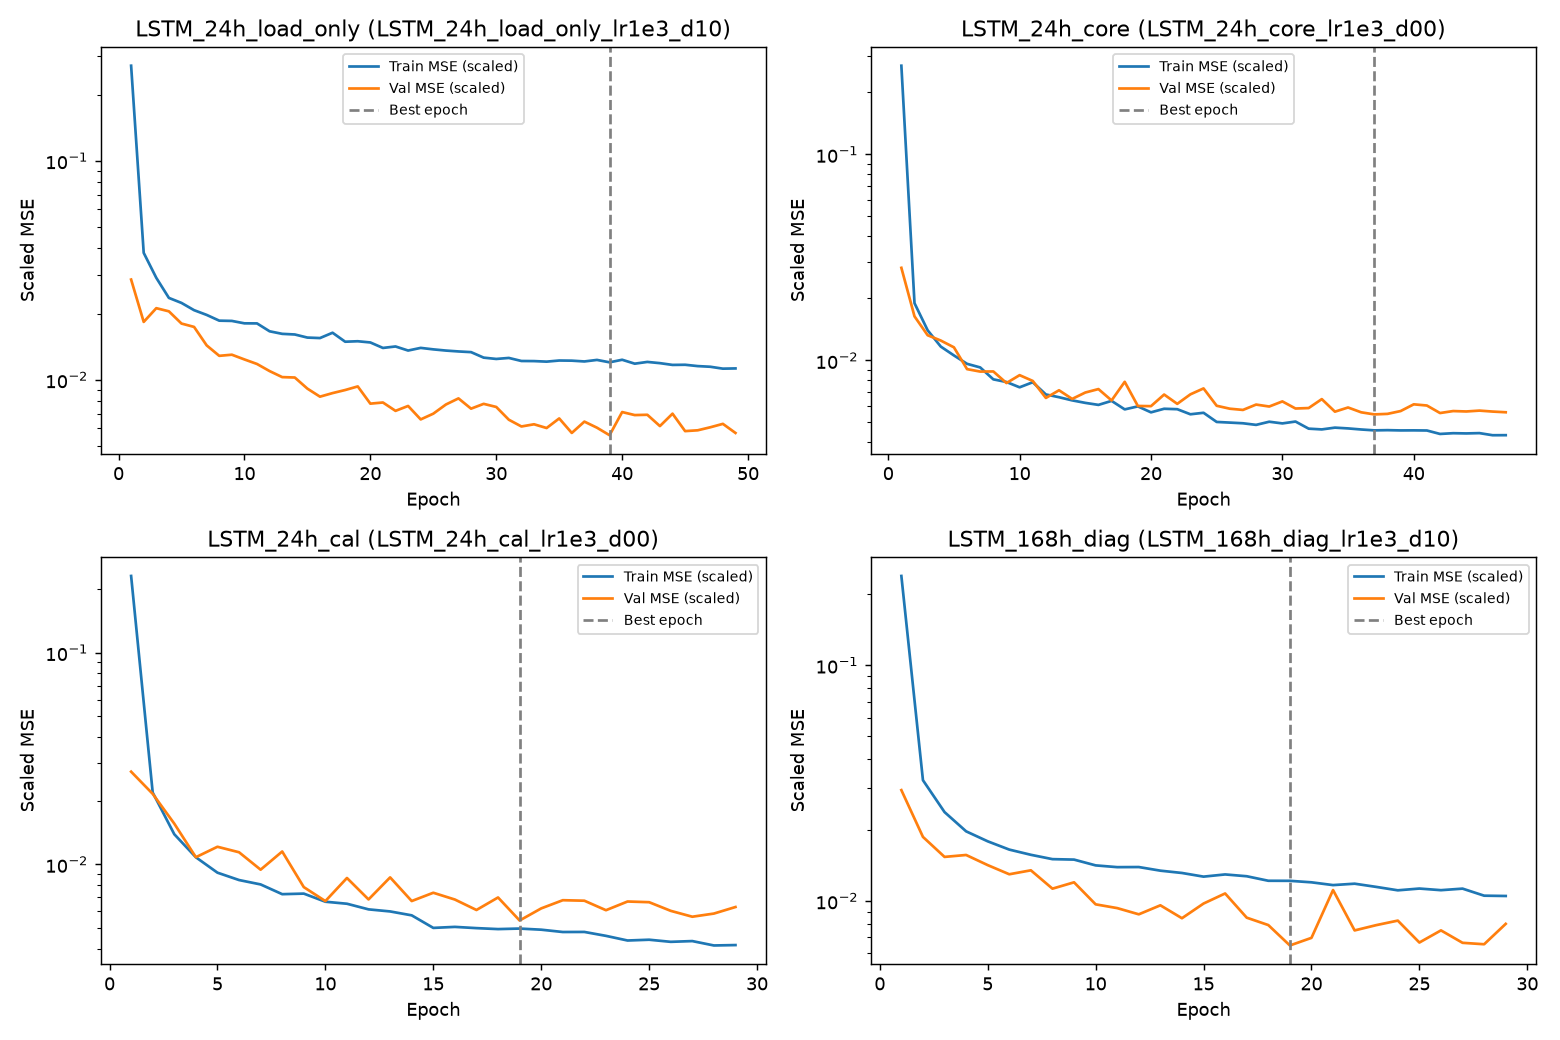

In [7]:
show_doc('docs/results/lstm_findings.md')
display(Image(filename=str(ROOT / 'outputs/figures' / 'lstm_learning_curves.png')))


## 7. Đánh giá Walk-Forward trên Test, Kiểm định Diebold–Mariano & Phân tích Lỗi (S8)

Tất cả mô hình đã khóa trọng số và scaler được đánh giá công bằng trên cùng **3.947 điểm Test** theo giao thức `predict → score → reveal`, kèm kiểm định ý nghĩa thống kê **Diebold–Mariano** và phân tích sai số theo giờ địa phương, ngày lễ, mùa.


### Bảng xếp hạng chính thức trên tập Test

Model,Scored,MAE (kW),RMSE (kW),MAPE (%)
XGB_best,"3,947","3,564.37","5,499.38",1.7776
LSTM_core,"3,947","4,156.48","5,872.02",2.1322
XGB_4var,"3,947","3,756.09","5,889.87",1.8802
VAR,"3,947","4,183.93","6,259.22",2.0989
LSTM_best,"3,947","4,557.90","6,433.83",2.4024
seasonal24,"3,947","7,716.33","13,502.14",3.8434
seasonal168,"3,947","12,247.95","19,011.91",5.5608
persistence,"3,947","16,345.12","25,507.75",8.7756


### Kiểm định Diebold–Mariano (Squared Error Loss, h = 1)

Model A,Model B,DM Stat,p-value,Significant (5%),Better Model
XGB_best,LSTM_best,-6.3783,1.790e-10,True,XGB_best
XGB_best,VAR,-6.3744,1.837e-10,True,XGB_best
LSTM_best,VAR,1.1930,2.329e-01,False,VAR
XGB_best,seasonal168,-22.7686,9.397e-115,True,XGB_best
LSTM_best,seasonal168,-21.2928,1.325e-100,True,LSTM_best
XGB_4var,LSTM_core,0.1275,8.986e-01,False,LSTM_core


### So sánh sai số giữa Ngày lễ và Ngày thường (`XGB_best` vs `LSTM_core` vs `LSTM_best` vs `VAR`)

Day Type,Model,Samples,MAE (kW),RMSE (kW),MAPE (%)
holiday,VAR,72,"6,596.30","9,748.89",5.3237
holiday,XGB_best,72,"10,317.47","15,288.08",9.0753
holiday,LSTM_best,72,"10,206.26","12,212.17",7.6142
holiday,LSTM_core,72,"5,398.01","7,313.79",4.3263
regular_day,VAR,"3,875","4,139.11","6,175.75",2.0390
regular_day,XGB_best,"3,875","3,438.90","5,144.15",1.6420
regular_day,LSTM_best,"3,875","4,452.95","6,276.32",2.3056
regular_day,LSTM_core,"3,875","4,133.41","5,841.86",2.0914


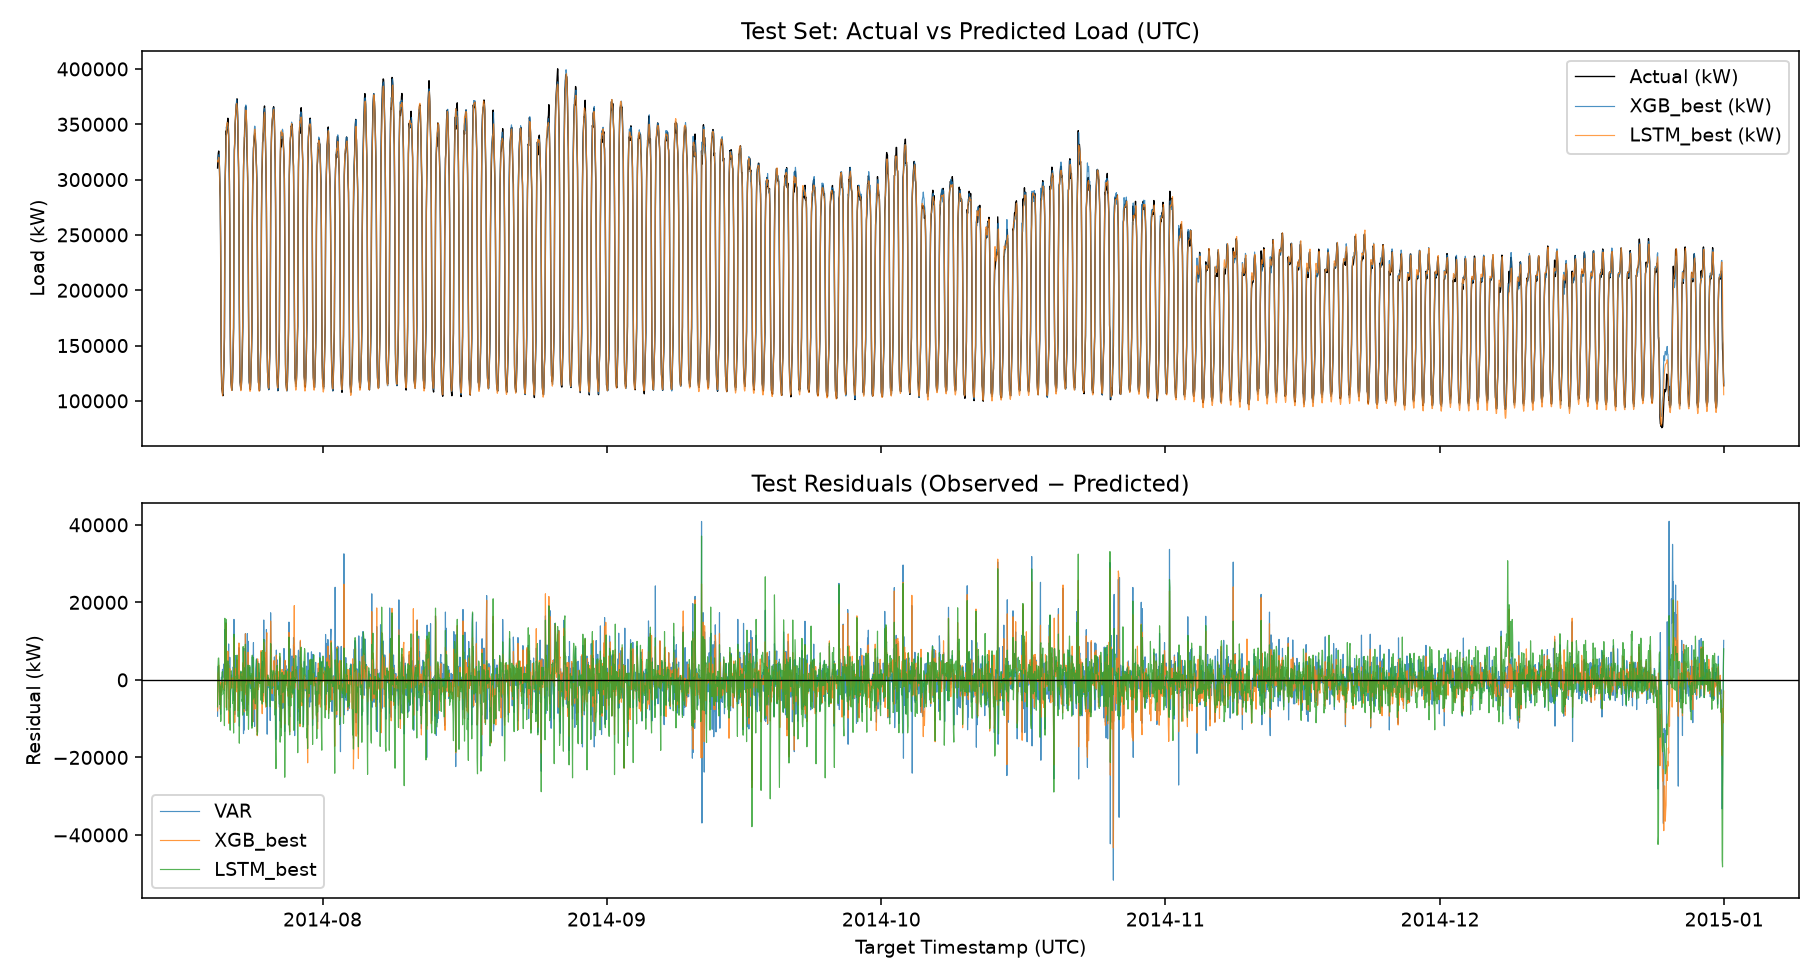

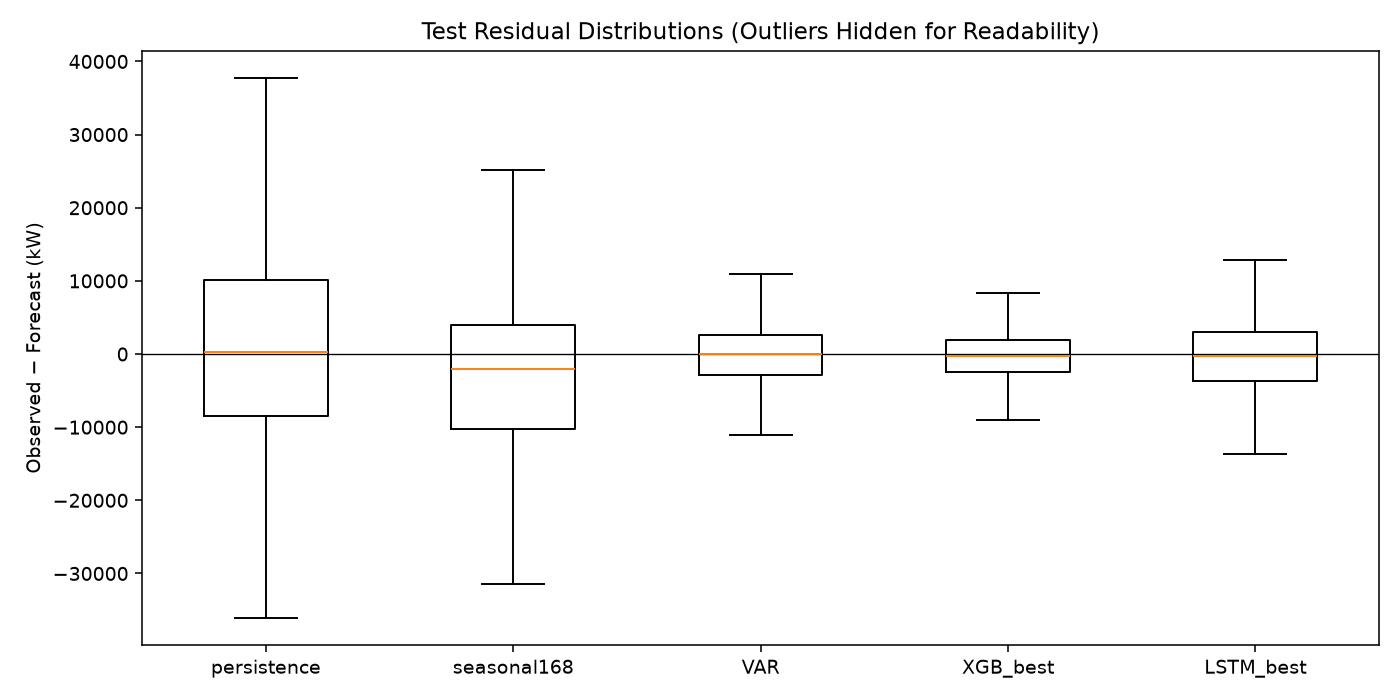

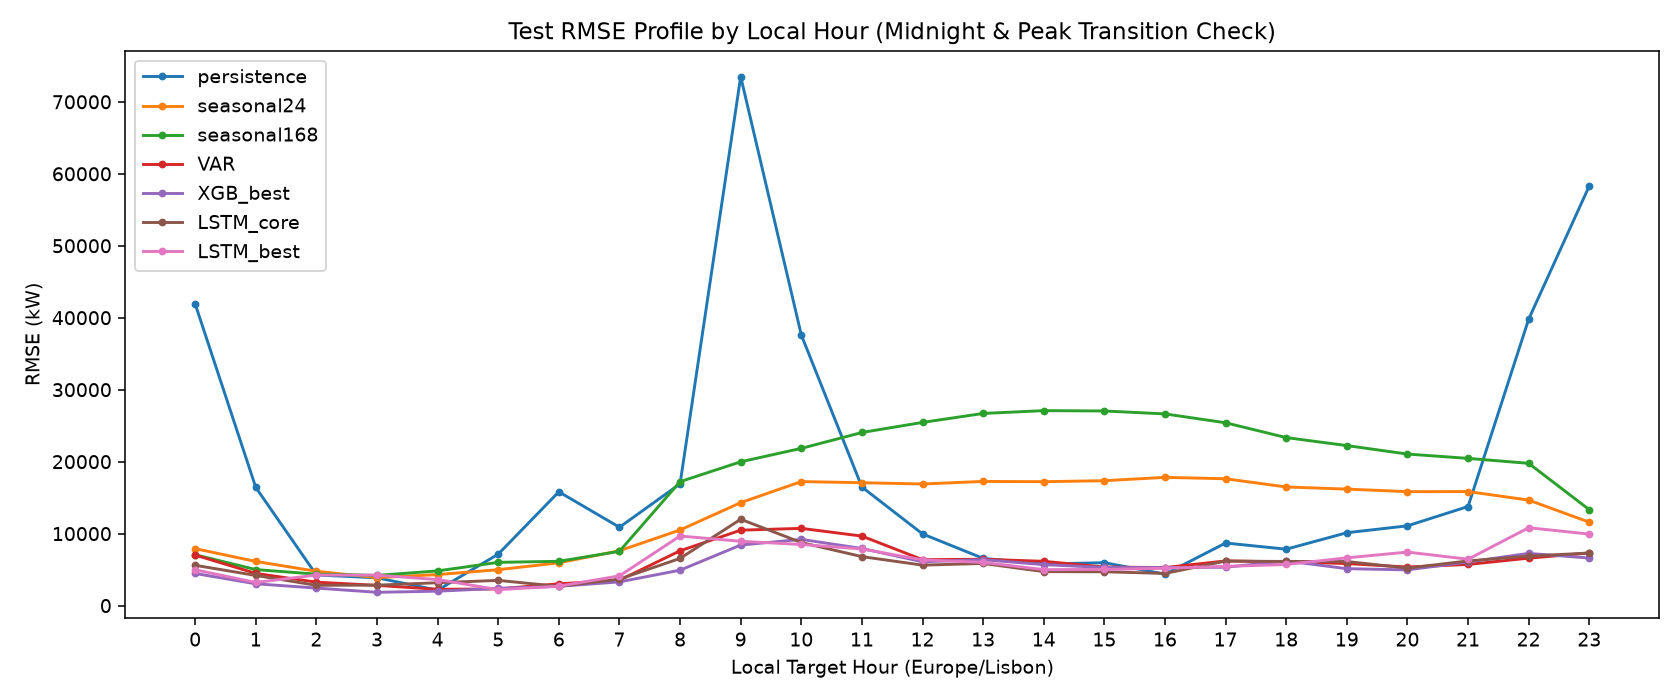

In [8]:
display(Markdown('### Bảng xếp hạng chính thức trên tập Test'))
leaderboard = test_metrics[['model', 'n_scored', 'mae_mw', 'rmse_mw', 'mape_percent']].rename(
    columns={'model': 'Model', 'n_scored': 'Scored', 'mae_mw': 'MAE (kW)', 'rmse_mw': 'RMSE (kW)', 'mape_percent': 'MAPE (%)'}
)
display(leaderboard.style.format({'Scored': '{:,}', 'MAE (kW)': '{:,.2f}', 'RMSE (kW)': '{:,.2f}', 'MAPE (%)': '{:.4f}'}).hide(axis='index'))

display(Markdown('### Kiểm định Diebold–Mariano (Squared Error Loss, h = 1)'))
dm_view = dm_test.rename(columns={
    'model_a': 'Model A', 'model_b': 'Model B', 'dm_stat': 'DM Stat',
    'p_value': 'p-value', 'significant_5pct': 'Significant (5%)', 'better_model': 'Better Model'
})
display(dm_view.style.format({'DM Stat': '{:.4f}', 'p-value': '{:.3e}'}).hide(axis='index'))

display(Markdown('### So sánh sai số giữa Ngày lễ và Ngày thường (`XGB_best` vs `LSTM_core` vs `LSTM_best` vs `VAR`)'))
hol_view = grouped_errors[
    (grouped_errors['dimension'] == 'holiday_group') &
    (grouped_errors['model'].isin(['VAR', 'XGB_best', 'LSTM_core', 'LSTM_best']))
][['group', 'model', 'n', 'mae', 'rmse', 'mape_percent']].rename(
    columns={'group': 'Day Type', 'model': 'Model', 'n': 'Samples', 'mae': 'MAE (kW)', 'rmse': 'RMSE (kW)', 'mape_percent': 'MAPE (%)'}
)
display(hol_view.style.format({'Samples': '{:,}', 'MAE (kW)': '{:,.2f}', 'RMSE (kW)': '{:,.2f}', 'MAPE (%)': '{:.4f}'}).hide(axis='index'))

for fn in ['actual_vs_predicted.png', 'residual_distributions.png', 'grouped_error_profiles.png']:
    display(Image(filename=str(ROOT / 'outputs/figures' / fn)))


## 8. Kết luận cuối cùng, Trả lời 6 câu hỏi đề bài & Giới hạn


In [9]:
show_doc('docs/results/final_report.md')


### 1. Objective, Official Dataset & GPU Pipeline

- **Dataset:** `UCI ElectricityLoadDiagrams20112014 + Open-Meteo ERA5 Portugal` — 3 full calendar years (`2012-01-01` → `2014-12-31` UTC, `26,304` hourly steps, stable active-client cohort, DST-adjusted, paired with clean population-weighted ERA5 weather for Lisbon/Porto/Coimbra).
- **Hardware Acceleration:** XGBoost 3.4.1 CUDA + PyTorch 2.14.1+cu130 LSTM executed natively on **NVIDIA GeForce RTX 5050**.
- **Leakage Control:** Chronological `70/15/15` split + 3-fold expanding-window CV inside train; train-only EDA and scaler; locked `predict → score → reveal` test walk-forward.

### 2. Official Test Leaderboard

| Model | MAE (kW) | RMSE (kW) | MAPE (%) |
|---|---:|---:|---:|
| `XGB_best` | 3,564.37 | 5,499.38 | 1.7776 |
| `LSTM_core` | 4,156.48 | 5,872.02 | 2.1322 |
| `XGB_4var` | 3,756.09 | 5,889.87 | 1.8802 |
| `VAR` | 4,183.93 | 6,259.22 | 2.0989 |
| `LSTM_best` | 4,557.90 | 6,433.83 | 2.4024 |
| `seasonal24` | 7,716.33 | 13,502.14 | 3.8434 |
| `seasonal168` | 12,247.95 | 19,011.91 | 5.5608 |
| `persistence` | 16,345.12 | 25,507.75 | 8.7756 |

Best model on held-out test: **`XGB_best`** (MAE `3,564.37`, RMSE `5,499.38 kW`, MAPE `1.7776%`).

### 3. Answers to the 6 Assignment Questions (Evidence-Backed)

#### Q1. Biến thời tiết nào liên hệ mạnh nhất với điện năng?
- Train Pearson / Spearman correlation với `load`: `temp` (`r=0.6767`, `ρ=0.6018`), `humidity` (`r=-0.6404`, `ρ=-0.6016`), `wind_speed` (`r=0.1113`, `ρ=0.1202`).
- SHAP Group Attribution trên `XGB_full`: `temperature_lags` = `1,702.7`, `humidity_lags` = `739.9`, `wind_speed_lags` = `324.7`, `cross_interactions` = `2,700.7` (kW). Lưu ý đây là liên hệ dự báo, không chứng minh nhân quả.

#### Q2. Khi nào VAR thất bại?
- Sau khi sửa flaw v1 (sai phân `d=1` theo Slide 5 và train 100% tập train `18,411` giờ), `VAR(24)` đạt ổn định (`max |λ|=0.9998 < 1`) nhưng vẫn kém ML/DL vì giả định tuyến tính không nắm được tương tác phi tuyến nhiệt độ–tải, hiệu ứng ngày lễ (`is_holiday`) và biến động mạnh lúc chuyển pha giờ cao điểm.

#### Q3. XGBoost học được thông tin gì từ thời tiết và feature engineering?
- Ablation trên Validation: `XGB_load_only` RMSE `4,577.17` → `XGB_load_calendar` `4,463.62` → `XGB_full` `4,358.22` (kW); `XGB_load_weather` (4 biến thuần) đạt `4,514.44`.
- SHAP xác nhận lịch sử phụ tải ngắn/tuần và đặc trưng lịch (`calendar_dst_holiday`) đóng góp lớn nhất, trong khi `hdd_proxy`/`cdd_proxy` và nhiệt độ tinh chỉnh phản ứng phi tuyến theo mùa.

#### Q4. LSTM thể hiện chu kỳ ngày/tuần như thế nào?
- Thực nghiệm đối chứng trực tiếp trên RTX 5050 giải quyết dứt điểm hạn chế v1: `LSTM_24h_core` (24h thuần 4 biến) đạt Val RMSE `5,928.51 kW` vs `LSTM_24h_cal` (thêm kênh lịch) `5,903.38 kW` vs `LSTM_168h_diag` (cửa sổ 168h = 1 tuần) `6,444.57 kW`. Điều này chứng minh nhận định ở Slide 10 (`chapter4-5.pdf`): LSTM xử lý tốt chu kỳ ngắn/ngày 24h nhưng suy giảm trên chuỗi rất dài 168 bước.
- Residual ACF trên Test: `LSTM_best` vẫn còn tự tương quan ở lag-24 (`0.4965`) và lag-168 (`0.4505`), trong khi `XGB_best` khử gần như triệt để (`-0.0357` và `0.0708`).

#### Q5. LSTM có bị overfitting không?
- Trên validation, `LSTM_24h_cal` chọn thử nghiệm `lr1e3_d00` (`dropout=0.0`, `weight_decay=0.0`) với `ReduceLROnPlateau` và `EarlyStopping` (`patience=10`, dừng ở epoch `29`, khôi phục best epoch `19`, Train MSE scaled = `0.005131` vs Val MSE scaled = `0.005427`).
- Tuy nhiên khi đánh giá trên Test, `LSTM_24h_cal` (`6,433.83 kW`) tổng quát hóa kém hơn `LSTM_core` (`5,872.02 kW`), cho thấy việc mở rộng từ 4 lên 13 kênh mà không có `dropout` đã dẫn tới hiện tượng quá khớp nhẹ vào giai đoạn validation (và biến động giữa các seed: `6,025.87 ± 174.77 kW`).

#### Q6. Machine Learning (XGBoost) và Deep Learning (LSTM) khác nhau thế nào?
- Khi dùng đúng 4 biến thô (`XGB_4var` vs `LSTM_core`), hai mô hình cho kết quả tương đương về mặt thống kê (`5,889.87` vs `5,872.02 kW`, DM `p = 0.8986`). Tuy nhiên khi bổ sung đầy đủ đặc trưng bảng (lags tuần `lag47`/`lag167`, calendar/DST/holiday, và tương tác phi tuyến `load_per_temp_k`, `hdd_proxy`/`cdd_proxy`), `XGB_full` vươn lên dẫn đầu vượt trội (`5,499.38 kW`, DM `p = 1.79e-10`), giải thích minh bạch qua SHAP và train chỉ mất `3.41s` trên RTX 5050.

### 4. Giới hạn và Rủi ro còn lại

- **Proxy thời tiết tái phân tích:** ERA5 đại diện cho 3 đô thị lớn của Bồ Đào Nha (Lisbon/Porto/Coimbra) theo trọng số `0.50/0.35/0.15`, không phải cảm biến đặt tại từng khách hàng trong 321 hộ/cơ sở của UCI.
- **Lệch mùa giữa các phân vùng đơn lẻ:** Test (`2014-07` → `2014-12`) phủ Hè–Thu–đầu Đông, trong khi Validation (`2014-02` → `2014-07`) phủ cuối Đông–Xuân–đầu Hè; vì vậy không dùng Test để tuning lại sau khi khóa cấu hình.
- **Giả định vận hành 1-step:** Giao thức `predict → score → reveal` giả định giá trị phụ tải thực tế của giờ vừa kết thúc sẵn sàng ngay để dự báo giờ tiếp theo.